# Classify samples to archetypes and map to reference using ArcheTypist

In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import celltypist
import archetypist
import session_info

%config InlineBackend.figure_format = 'retina'

Explain more about cell fractions

In this notebook, we analyse a public PBMC scRNA-seq dataset of COVID-19 patients and controls and classify the samples into broad blood archetypes and fine-grained blood composition subtypes. This allows us to test whether blood archetypes are associated with clinical metadata such as infection status.

The workflow consists of the following steps:

1. Prepare data by <b>transferring cell annotation labels</b> using CellTypist to achieve labels matching with the reference</b>
 
2. Build a  <b>sample-by-cell-type AnnData</b> based on cell type fractions
 
3. <b>Classify samples into archetypes</b> and fine-grained composition subtypes
 
4. <b>Map samples to reference embedding</b>
 
5. <b>Predict features such as CMV status</b> based on cell composition

In [4]:
# Data from Stephenson et al. 2021 https://covid19.cog.sanger.ac.uk/submissions/release1/haniffa21.processed.h5ad
adata = sc.read_h5ad("/nfs/casm/team215mg/users/od5/datasets/haniffa21.processed.h5ad")

In [5]:
adata

AnnData object with n_obs × n_vars = 647366 × 24929
    obs: 'sample_id', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'full_clustering', 'initial_clustering', 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id'
    var: 'feature_types'
    uns: 'hvg', 'leiden', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    layers: 'raw'

In [6]:
# Subset data for demo
adata = adata[adata.obs['Site'].isin(['Ncl'])]

In [7]:
# Downsample for faster running (for demo, normally use full data)
sampled_cell_index = celltypist.samples.downsample_adata(adata, mode = 'total', n_cells = 100000, by = 'full_clustering', return_index = True)

In [8]:
adata_subsample = adata[sampled_cell_index]

## 1. Transfer cell annotation labels matching reference using CellTypist

In [9]:
# Normalize and log1p for CellTypist
sc.pp.normalize_total(adata_subsample, target_sum=10000)
sc.pp.log1p(adata_subsample)

We first transfer cell type labels from the Cardinal dataset to obtain a cell type annotation that can be used to classify blood archetypes.

In [10]:
# Load Cardinal PBMC CellTypist model
model = archetypist.cardinal_celltypist_pbmc_model()

# if using your own model, load as follows
# model = celltypist.models.Model.load(model = 'model.pkl')

In [11]:
model

CellTypist model with 79 cell types and 3646 features
    date: 2026-03-12 04:20:12.634786
    cell types: ASDC, B_CD5, ..., pDC
    features: PLEKHN1, HES4, ..., MT-CYB

In [12]:
# CellTypist label transfer of Cardinal PBMC annotations
predictions = celltypist.annotate(adata_subsample, model = model, majority_voting = True)

🔬 Input data has 100000 cells and 24929 genes
🔗 Matching reference genes in the model
🧬 3487 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Can not detect a neighborhood graph, will construct one before the over-clustering
⛓️ Over-clustering input data with resolution set to 25
🗳️ Majority voting the predictions
✅ Majority voting done!


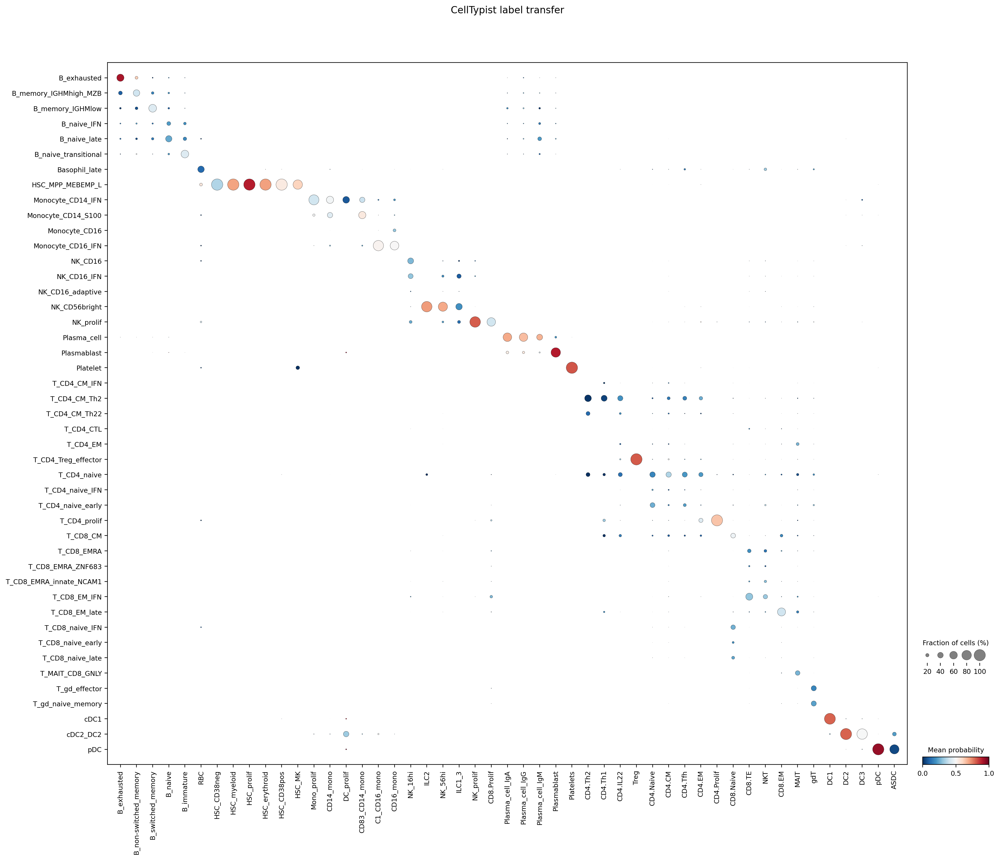

In [13]:
# Plot predictions against original annotations and transfer predictions to new anndata
celltypist.dotplot(predictions, use_as_reference = 'full_clustering', use_as_prediction = 'majority_voting')
adata2 = predictions.to_adata()

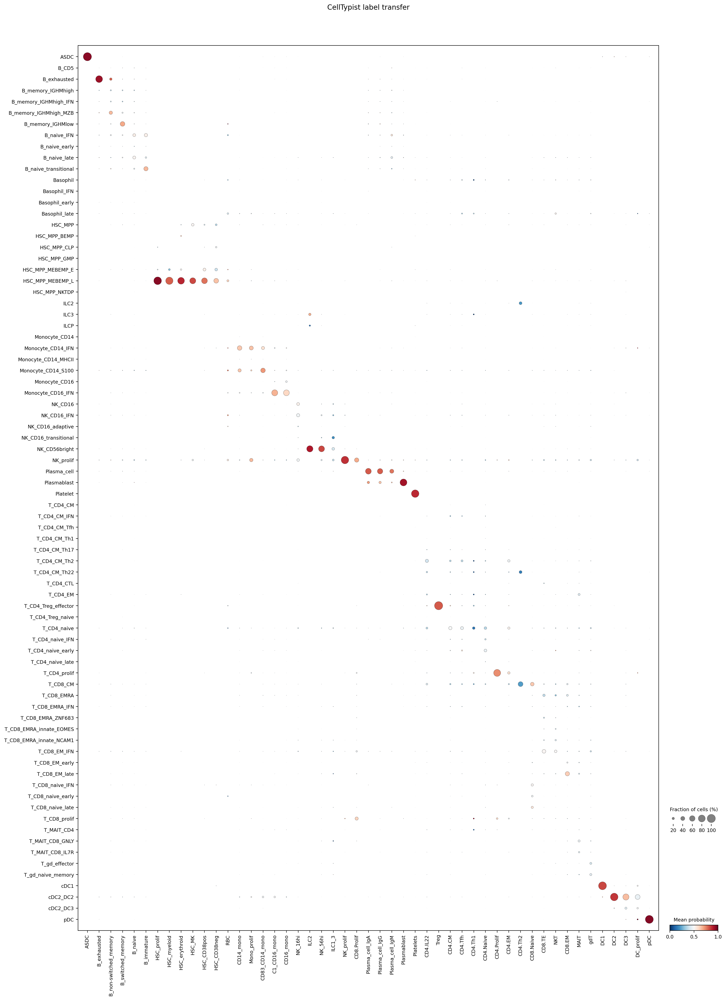

In [14]:
celltypist.dotplot(predictions, use_as_reference = 'full_clustering', use_as_prediction = 'predicted_labels')

In [15]:
adata2

AnnData object with n_obs × n_vars = 100000 × 24929
    obs: 'sample_id', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'full_clustering', 'initial_clustering', 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'predicted_labels', 'over_clustering', 'majority_voting', 'conf_score'
    var: 'feature_types'
    uns: 'hvg', 'leiden', 'neighbors', 'pca', 'umap', 'log1p'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    layers: 'raw'
    obsp: 'connectivities', 'distances'

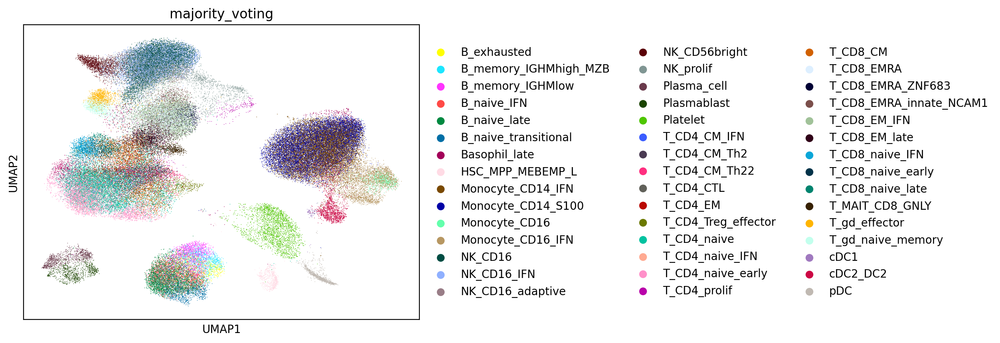

In [16]:
sc.pl.umap(adata2, color="majority_voting")

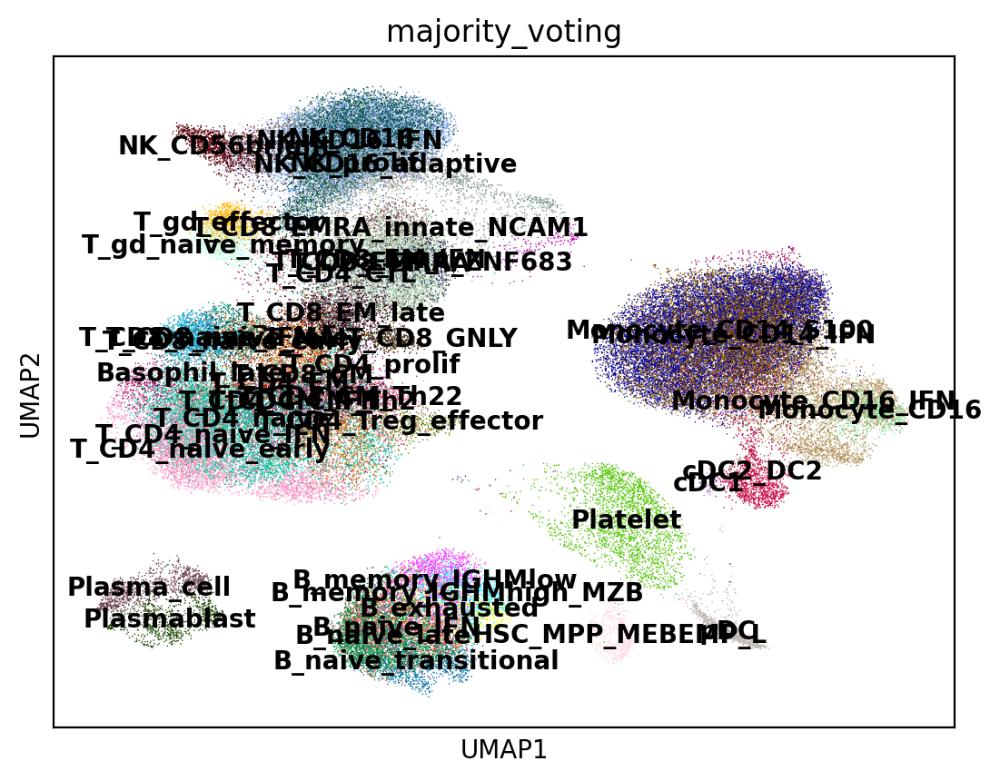

In [17]:
sc.pl.umap(adata2, color="majority_voting", legend_loc="on data")

## 2. Build a sample-by-cell-type AnnData based on cell type fractions

Using the transferred cell type labels, we then construct an AnnData object of samples by cell types for grouping samples into archetypes.

In [71]:
# Build a sample-by-cell-type fraction AnnData from a cell-level AnnData object
adata_frac = archetypist.make_celltype_fraction_adata(adata2,
                                                      sample_col="sample_id",
                                                      celltype_col="predicted_labels",
                                                      exclude_meta=None,)

In [72]:
adata_frac

AnnData object with n_obs × n_vars = 72 × 78
    obs: 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id'

We now have an anndata object of samples x cell type fractions (instead of cells x genes). We next perform PCA and identify neighbours in the cell type fraction space and visualise samples on a UMAP.

In [73]:
sc.pp.pca(adata_frac)
sc.pp.neighbors(adata_frac)

In [74]:
sc.tl.umap(adata_frac, spread=2, min_dist=0.5)

... storing 'Resample' as categorical
... storing 'Collection_Day' as categorical
... storing 'Sex' as categorical
... storing 'Age_interval' as categorical
... storing 'Swab_result' as categorical
... storing 'Status' as categorical
... storing 'Smoker' as categorical
... storing 'Status_on_day_collection' as categorical
... storing 'Status_on_day_collection_summary' as categorical
... storing 'Days_from_onset' as categorical
... storing 'Site' as categorical
... storing 'time_after_LPS' as categorical
... storing 'Worst_Clinical_Status' as categorical
... storing 'Outcome' as categorical


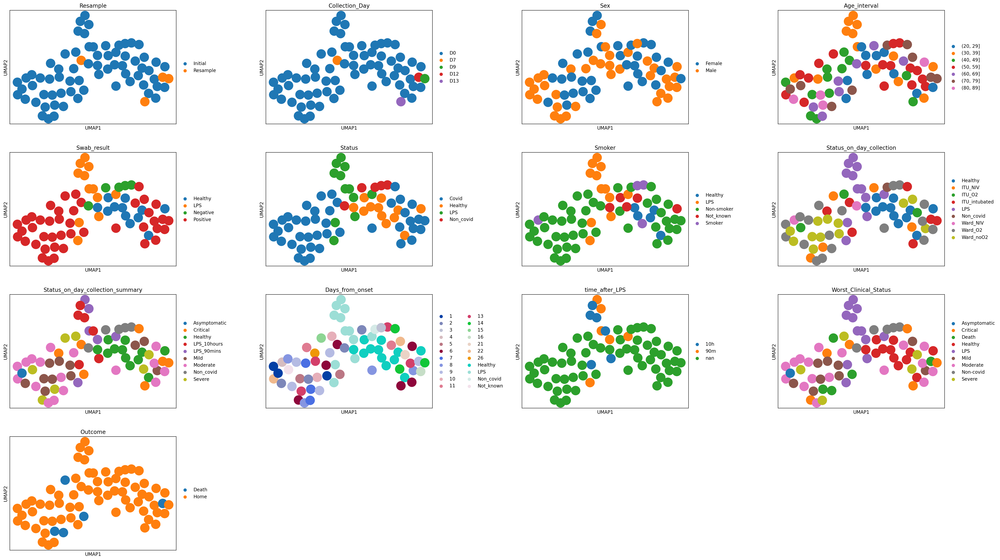

In [75]:
# Examine metadata fields
sc.pl.umap(adata_frac, color=['Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker',
                              'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset',
                              'time_after_LPS', 'Worst_Clinical_Status', 'Outcome'], wspace=0.4)

## 3. Classify samples into archetypes

We then use an ArcheTypist model (sample-level CellTypist model) trained on the Cardinal dataset to classify samples into archetypes in the query dataset. In the second notebook we train a model and evaluate its performance.

In [ ]:
archetype_model = archetypist.cardinal_archetype_model()

# for classifying fine-grained composition subtypes, use archetypist.cardinal_comp_cluster_model()

In [ ]:
predictions = celltypist.annotate(adata_frac, model = archetype_model, majority_voting = True)

# if using your own model:
# predictions = celltypist.annotate(adata_frac, model = ('model.pkl'), majority_voting = True)

⚠️ Warning: invalid expression matrix, expect ALL genes and log1p normalized expression to 10000 counts per cell. The prediction result may not be accurate
🔬 Input data has 72 cells and 78 genes
🔗 Matching reference genes in the model
🧬 78 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 5
🗳️ Majority voting the predictions
✅ Majority voting done!


In [78]:
adata_frac = predictions.to_adata()

We visualise predicted archetypes on a UMAP.

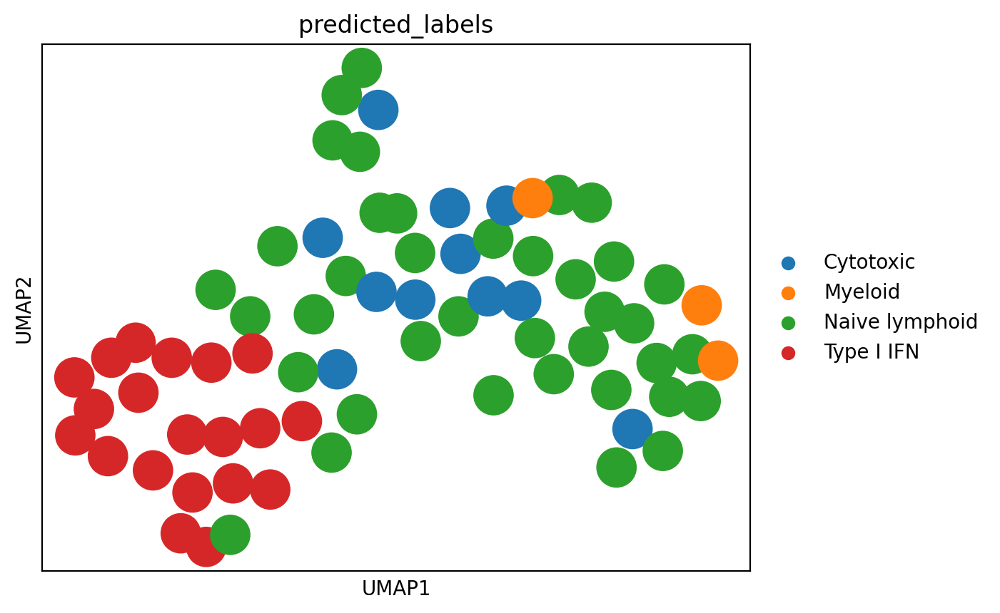

In [79]:
sc.pl.umap(adata_frac, color = ['predicted_labels'])

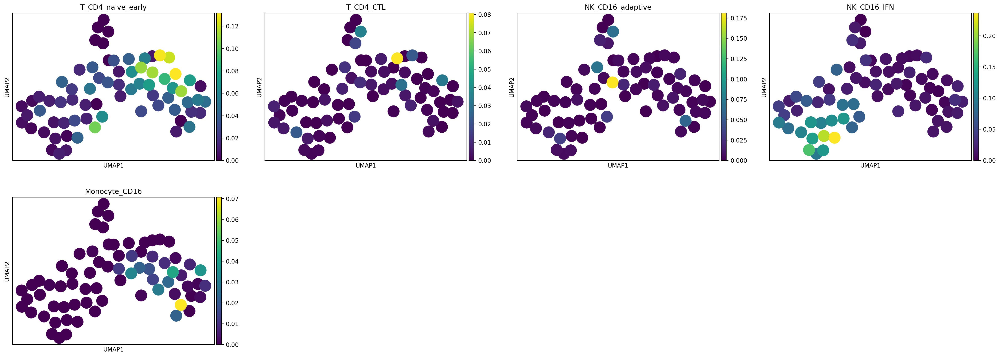

In [80]:
sc.pl.umap(adata_frac, color = ['T_CD4_naive_early', 'T_CD4_CTL', 'NK_CD16_adaptive', 'NK_CD16_IFN', 'Monocyte_CD16']) 

In [81]:
adata_frac

AnnData object with n_obs × n_vars = 72 × 78
    obs: 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'predicted_labels', 'over_clustering', 'majority_voting', 'conf_score'
    uns: 'pca', 'neighbors', 'umap', 'Resample_colors', 'Collection_Day_colors', 'Sex_colors', 'Age_interval_colors', 'Swab_result_colors', 'Status_colors', 'Smoker_colors', 'Status_on_day_collection_colors', 'Status_on_day_collection_summary_colors', 'Days_from_onset_colors', 'time_after_LPS_colors', 'Worst_Clinical_Status_colors', 'Outcome_colors', 'leiden', 'predicted_labels_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

## 4. Map samples to reference

For visualisation and an alternative approach to sample classification, we load a reference sample-level AnnData of the Cardinal PBMC atlas (we use synthetic data based on original cell composition distributions as original sample-level data requires biobank access).

We then use ArcheTypist to map query samples to this reference using nearest-neighbour similarity, and visualise query samples on the reference embedding.

In [137]:
# Load reference sample-level Cardinal PBMC object
adata_ref = sc.read_h5ad('cardinal_synthetic_reference.h5ad')

In [83]:
adata_ref

AnnData object with n_obs × n_vars = 3000 × 79
    obs: 'composition_cluster', 'archetype', 'synthetic', 'reference_group_n'
    uns: 'archetype_colors', 'composition_cluster_colors', 'synthetic_reference'
    obsm: 'X_draw_graph_fa'

In [100]:
# Map query samples onto a reference using nearest-neighbour similarity over shared cell-type fractions
adata_frac_mapped = archetypist.map_query_to_reference_embedding(
    adata_ref,
    adata_frac,
    embedding_key="X_draw_graph_fa")

... storing 'mapped_ref_sample' as categorical


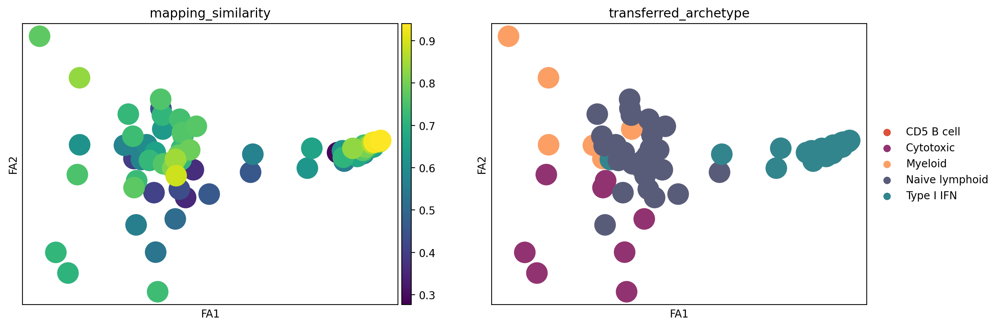

In [85]:
# Plot query samples mapped onto reference FA2 space
sc.pl.embedding(
    adata_frac_mapped,
    basis="draw_graph_fa",
    color=["mapping_similarity", "transferred_archetype"]
)

We then combine query and reference data to visualise both on the same embedding.

In [86]:
combined = archetypist.combine_reference_query_embedding(
    adata_ref,
    adata_frac_mapped,
    embedding_key="X_draw_graph_fa",
)

In [87]:
combined

AnnData object with n_obs × n_vars = 3072 × 79
    obs: 'composition_cluster', 'archetype', 'synthetic', 'reference_group_n', 'dataset', 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'predicted_labels', 'over_clustering', 'majority_voting', 'conf_score', 'mapped_ref_sample', 'mapping_distance', 'mapping_similarity', 'transferred_archetype', 'transferred_archetype_confidence', 'transferred_composition_cluster', 'transferred_composition_cluster_confidence'
    uns: 'archetype_colors', 'transferred_archetype_colors', 'composition_cluster_colors', 'transferred_composition_cluster_colors'
    obsm: 'X_draw_graph_fa', 'X_pca', 'X_umap'

... storing 'dataset' as categorical
... storing 'patient_id' as categorical


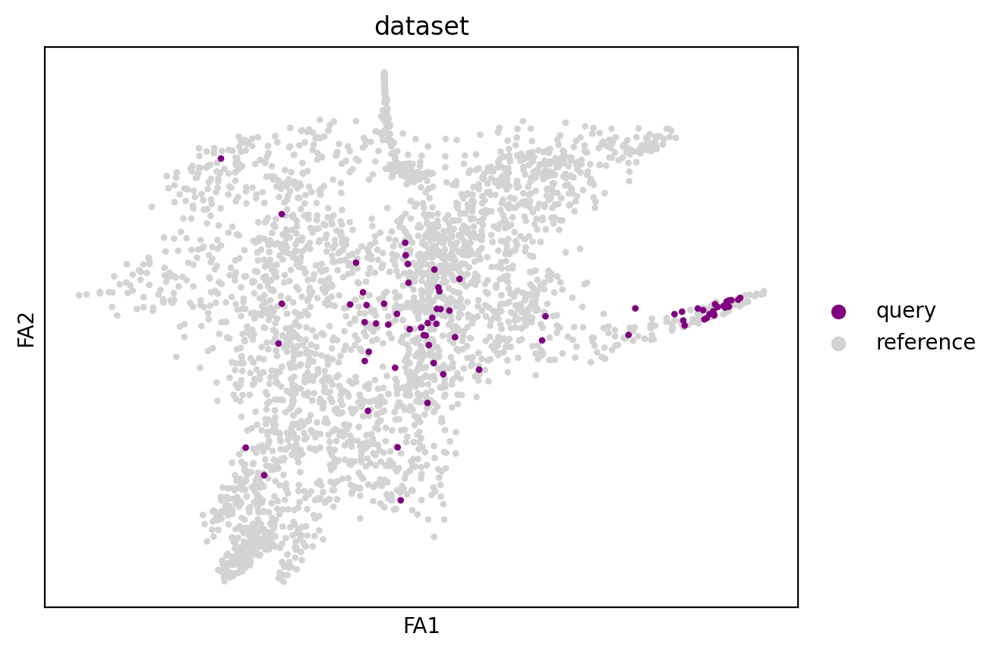

In [88]:
sc.pl.embedding(
    combined,
    basis="draw_graph_fa",
    palette={
        "query": "#800080",
        "reference": "#d3d3d3",
    },
    color=["dataset"]
)

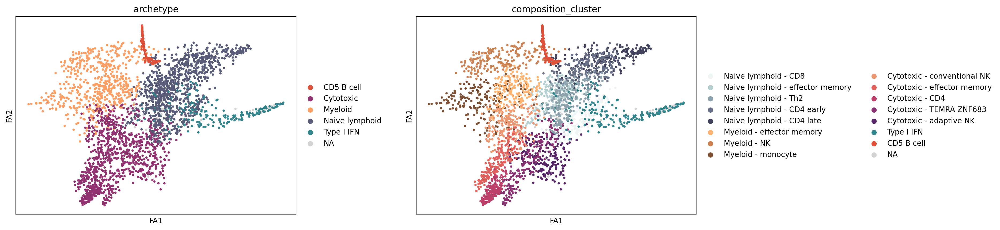

In [89]:
# Reference annotations
sc.pl.embedding(
    combined,
    basis="draw_graph_fa",
    color=["archetype", "composition_cluster"],
    wspace=0.3)

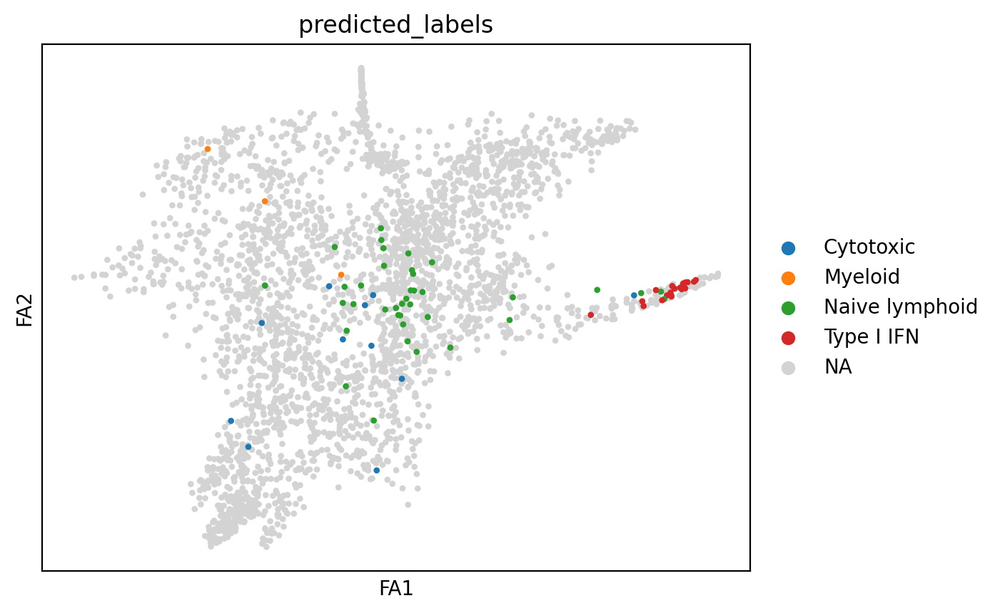

In [90]:
# Predicted archetype labels using logistic regression method
sc.pl.embedding(
    combined,
    basis="draw_graph_fa",
    color=["predicted_labels"],
    wspace=0.3
)

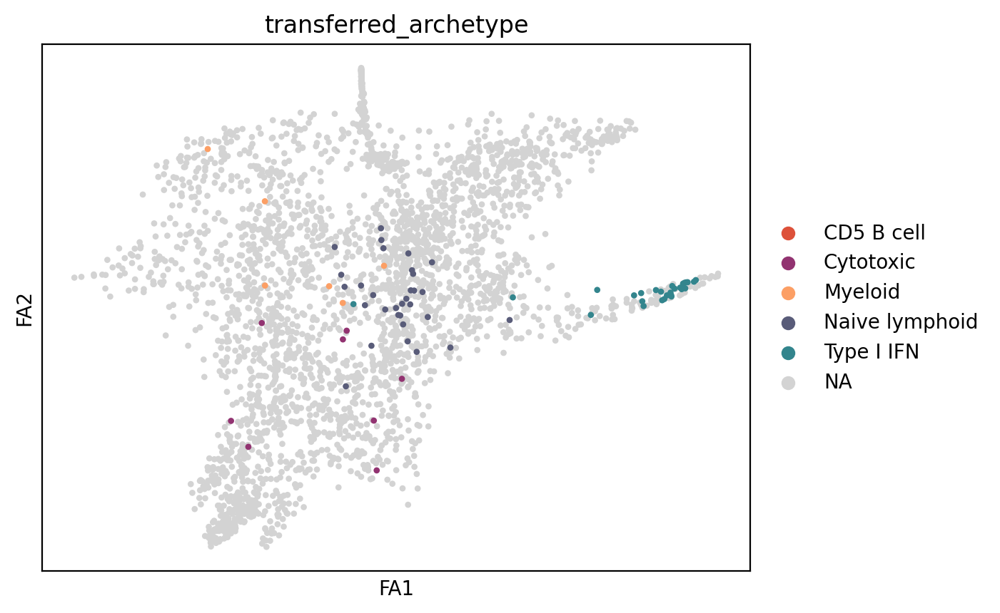

In [91]:
# Transferred archetype labels using nearest neighbour method
sc.pl.embedding(
    combined,
    basis="draw_graph_fa",
    color=["transferred_archetype"],
    wspace=0.3
)

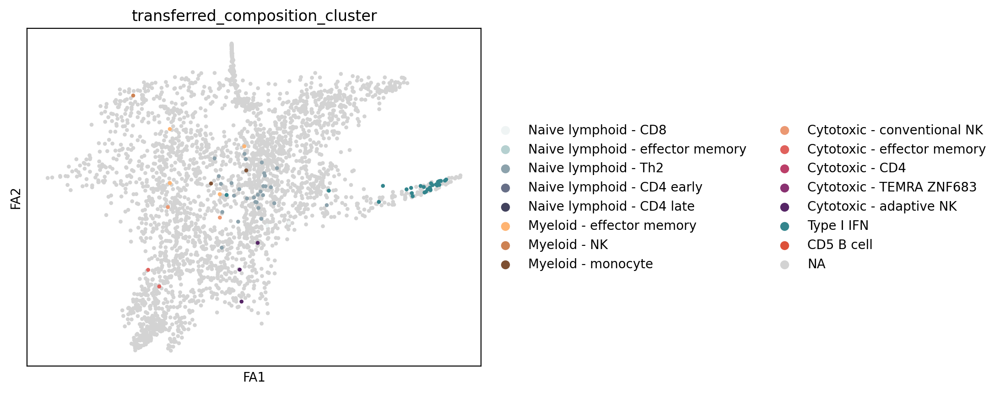

In [50]:
# Transferred composition subtype labels using nearest neighbour method
sc.pl.embedding(
    combined,
    basis="draw_graph_fa",
    color=["transferred_composition_cluster"],
    wspace=0.3
)

We see that the two label transfer methods produce largely similar results. The nearest neighbour method results are more aligned with positioning of the samples on the embedding.

We can then visualise features of the query dataset, such as disease status and test result on the embedding.

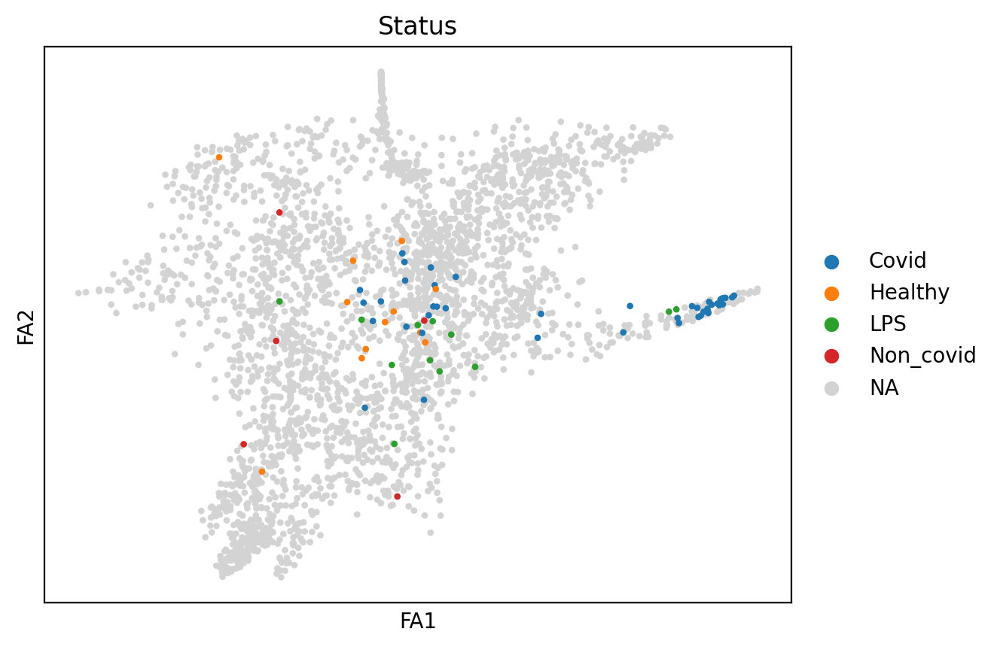

In [65]:
sc.pl.embedding(
    combined,
    basis="draw_graph_fa",
    color=["Status"],
    wspace=0.3
)

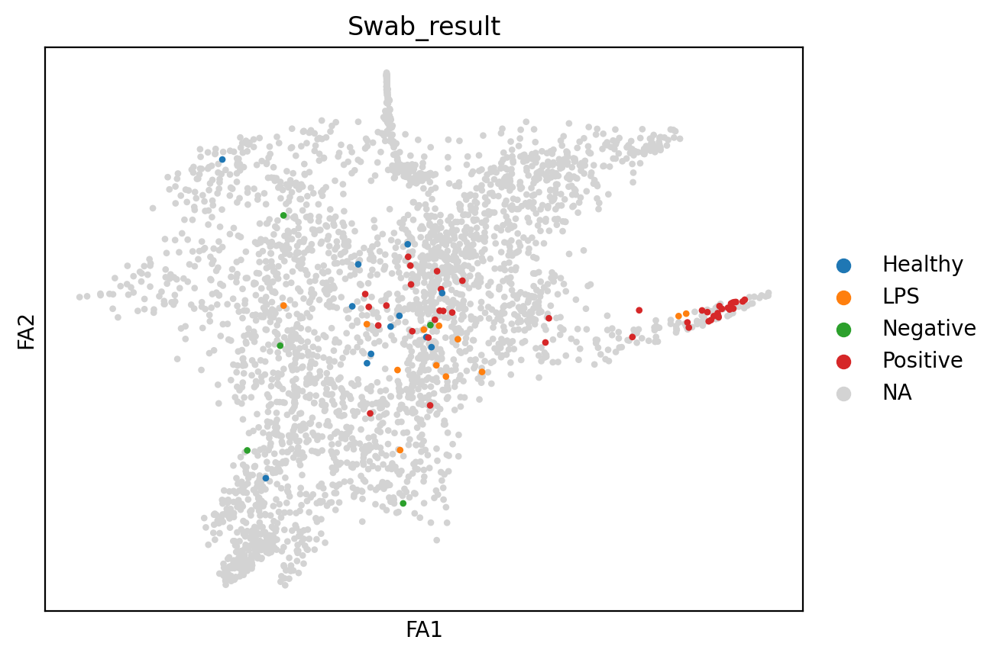

In [66]:
sc.pl.embedding(
    combined,
    basis="draw_graph_fa",
    color=["Swab_result"],
    wspace=0.3
)

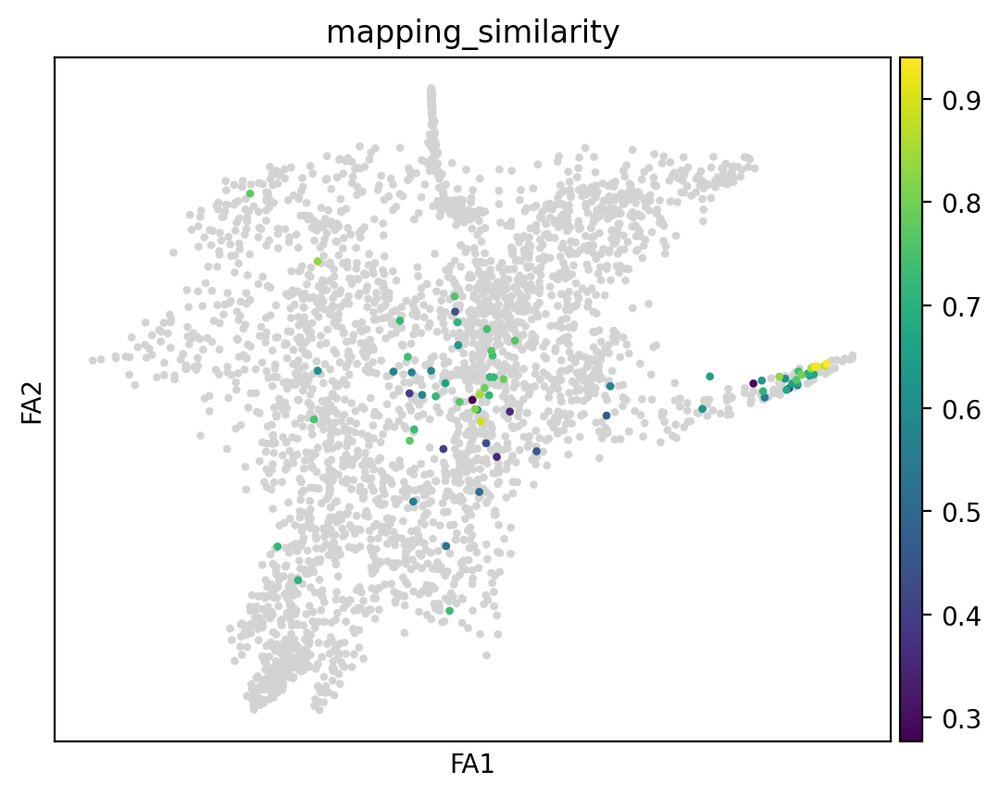

In [54]:
# Mapping similarity
sc.pl.embedding(
    combined,
    basis="draw_graph_fa",
    color=["mapping_similarity"]
)

<Axes: title={'center': 'Reference mapping'}>

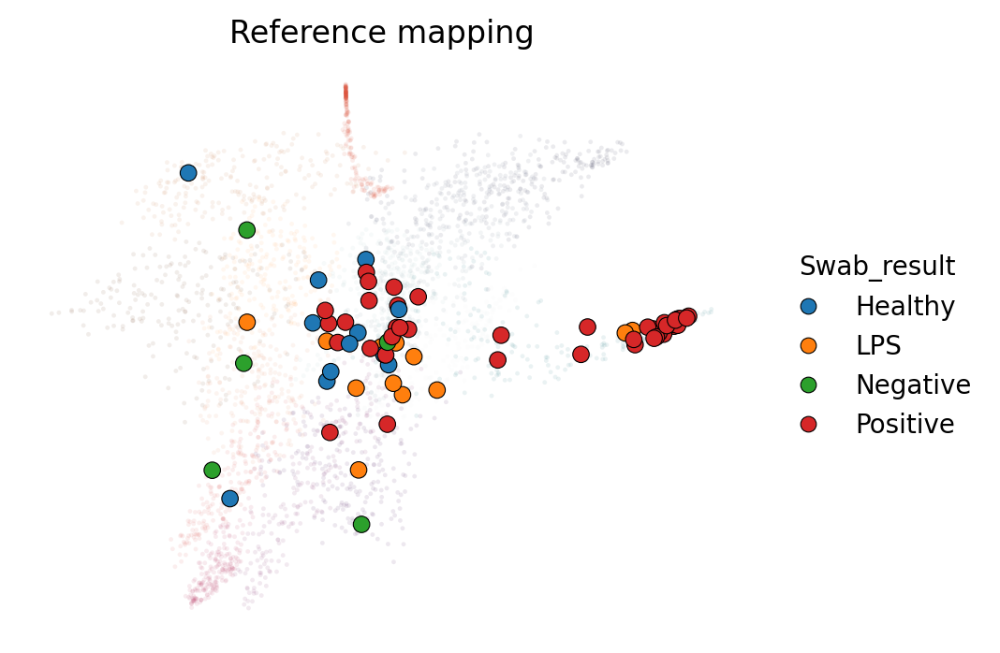

In [55]:
archetypist.plot_reference_mapping(
    combined,
    feature="Swab_result",
)

<Axes: title={'center': 'Reference mapping'}>

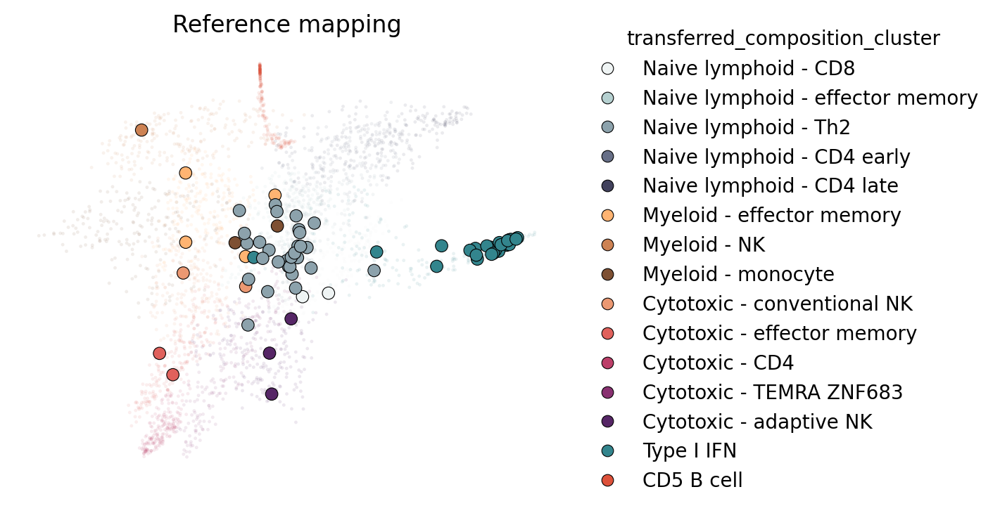

In [56]:
archetypist.plot_reference_mapping(
    combined,
    feature="transferred_composition_cluster",
)

Now that we have classified the samples in the query dataset into archetypes, we can test whether archetype status is associated with sample metadata, for example COVID-19 test result.

In [58]:
# Test enrichment of each archetype within each swab-result group using Fisher's exact test
# FDR correction is applied across all group–archetype comparisons

from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

group_col = "Swab_result"
category_col = "transferred_archetype"

# Keep only the columns needed and remove missing values
df = adata_frac_mapped.obs[[group_col, category_col]].dropna()

groups = df[group_col].unique()
categories = df[category_col].unique()

results = []

# Test each group–archetype combination against all other samples
for group in groups:
    for category in categories:

        in_group = df[group_col] == group
        in_category = df[category_col] == category

        a = (in_group & in_category).sum()
        b = (in_group & ~in_category).sum()
        c = (~in_group & in_category).sum()
        d = (~in_group & ~in_category).sum()

        oddsratio, p = fisher_exact([[a, b], [c, d]])

        results.append({
            group_col: group,
            category_col: category,
            "oddsratio": oddsratio,
            "p": p,
        })

# Combine results and correct for multiple testing
enrichment = pd.DataFrame(results)
enrichment["FDR"] = multipletests(enrichment["p"], method="fdr_bh")[1]

# Show most significant associations first
enrichment = enrichment.sort_values("FDR")

display(enrichment)

,Swab_result,transferred_archetype,oddsratio,p,FDR
11,Positive,Type I IFN,18.750000,0.000006,0.000098
3,Healthy,Type I IFN,0.000000,0.002455,0.019640
9,Positive,Cytotoxic,0.074830,0.005966,0.031818
13,Negative,Cytotoxic,18.600000,0.008393,0.033572
10,Positive,Myeloid,0.114286,0.035724,0.114317
1,Healthy,Cytotoxic,3.666667,0.122959,0.327891
15,Negative,Type I IFN,0.000000,0.149536,0.341796
2,Healthy,Myeloid,2.800000,0.260095,0.378319
6,LPS,Myeloid,2.800000,0.260095,0.378319
7,LPS,Type I IFN,0.280000,0.189659,0.378319


We see significant enrichment for multiple archetypes and visualise archetype distribution across test result classes. For example, the type I IFN archetype is significantly enriched in COVID-19 positive donors and depleted in healthy donors.

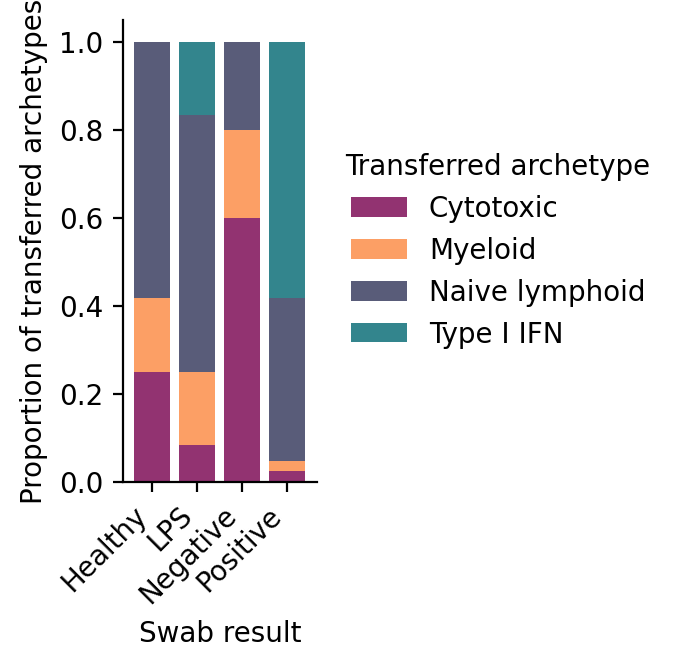

In [59]:
group_col = "Swab_result"
category_col = "transferred_archetype"
color_key = "transferred_archetype_colors"

df = adata_frac_mapped.obs[[group_col, category_col]].dropna().copy()

counts = pd.crosstab(df[group_col], df[category_col])
prop = counts.div(counts.sum(axis=1), axis=0)

palette = dict(zip(
    adata_frac_mapped.obs[category_col].cat.categories,
    adata_frac_mapped.uns[color_key],
))

colors = [palette[c] for c in prop.columns]

fig, ax = plt.subplots(figsize=(1.25, 3))

prop.plot(
    kind="bar",
    stacked=True,
    color=colors,
    edgecolor="none",
    width=0.8,
    ax=ax,
)

sns.despine()

ax.set_xlabel("Swab result")
ax.set_ylabel("Proportion of transferred archetypes")
ax.legend(
    title="Transferred archetype",
    frameon=False,
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout
plt.show()

## 5. Predict CMV status

Here we use another feature ArcheTypist to predict cytomegalovirus (CMV) serostatus relying on cell state composition using a pre-trained model based on biobank serology data. CMV infection induces a distinct cell type composition with expanded CD4+ CTL, CD8+ TEMRA and adaptive NK cell subsets which can be used to classify infection history.

In [ ]:
# Predict CMV status
artifact = archetypist.cmv_rf_model()
adata_frac_mapped = archetypist.predict_cmv(adata_frac_mapped, artifact = artifact)

... storing 'cmv_pred' as categorical


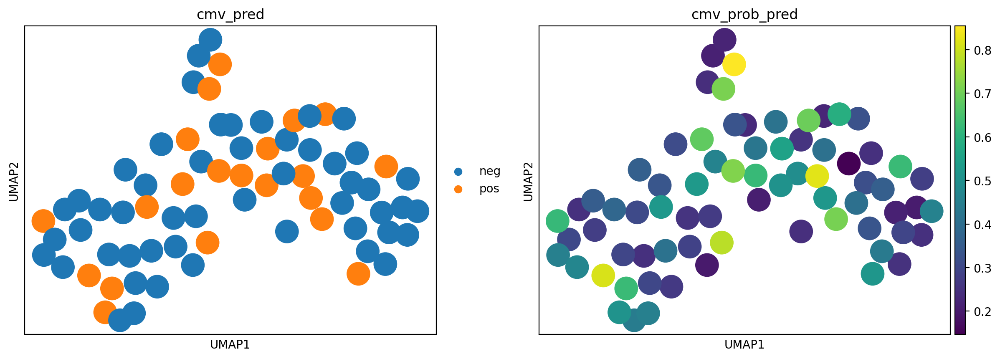

In [102]:
# Plot results on cell state fraction-based UMAP
sc.pl.umap(adata_frac, color=['cmv_pred', 'cmv_prob_pred'])

We then test enrichment of CMV serostatus in the transferred blood archetypes.

In [104]:
# Test enrichment of each archetype within each swab-result group using Fisher's exact test
# FDR correction is applied across all group–archetype comparisons

from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

group_col = "cmv_pred"
category_col = "transferred_archetype"

# Keep only the columns needed and remove missing values
df = adata_frac_mapped.obs[[group_col, category_col]].dropna()

groups = df[group_col].unique()
categories = df[category_col].unique()

results = []

# Test each group–archetype combination against all other samples
for group in groups:
    for category in categories:

        in_group = df[group_col] == group
        in_category = df[category_col] == category

        a = (in_group & in_category).sum()
        b = (in_group & ~in_category).sum()
        c = (~in_group & in_category).sum()
        d = (~in_group & ~in_category).sum()

        oddsratio, p = fisher_exact([[a, b], [c, d]])

        results.append({
            group_col: group,
            category_col: category,
            "oddsratio": oddsratio,
            "p": p,
        })

# Combine results and correct for multiple testing
enrichment = pd.DataFrame(results)
enrichment["FDR"] = multipletests(enrichment["p"], method="fdr_bh")[1]

# Show most significant associations first
enrichment = enrichment.sort_values("FDR")

display(enrichment)

,cmv_pred,transferred_archetype,oddsratio,p,FDR
1,pos,Cytotoxic,9.800000,0.006293,0.025172
5,neg,Cytotoxic,0.102041,0.006293,0.025172
2,pos,Myeloid,0.000000,0.171099,0.342199
6,neg,Myeloid,inf,0.171099,0.342199
3,pos,Type I IFN,0.571429,0.424015,0.565354
7,neg,Type I IFN,1.750000,0.424015,0.565354
0,pos,Naive lymphoid,0.988636,1.000000,1.000000
4,neg,Naive lymphoid,1.011494,1.000000,1.000000


As expected, the cytotoxic archetype is significantly associated with CMV positivity.

We next map the newly obtained sample-level annotations (archetype, fine-grained composition subtype, CMV status) to the original cell-level AnnData object to facilitate downstream analyses. This allows for example plotting the new annotations on the cell-level data.

In [126]:
# Map new sample-level metadata to original cell-level AnnData object
adata_subsample = archetypist.map_sample_obs_to_cells(
    adata_subsample,
    adata_frac_mapped,
    sample_col="sample_id",
    columns=[
        "transferred_archetype",
        "transferred_composition_cluster",
        "cmv_prob_pred",
        "cmv_pred",
    ],
)

... storing 'sample_id' as categorical
... storing 'cmv_pred' as categorical


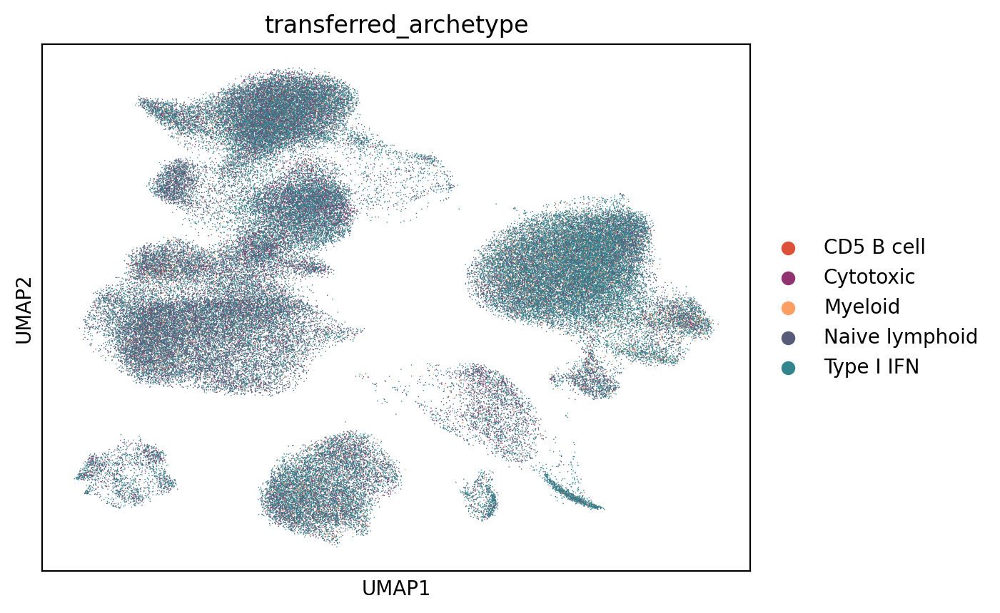

In [127]:
# Plot UMAP with archetypes coloured on cells
sc.pl.umap(adata_subsample, color="transferred_archetype")

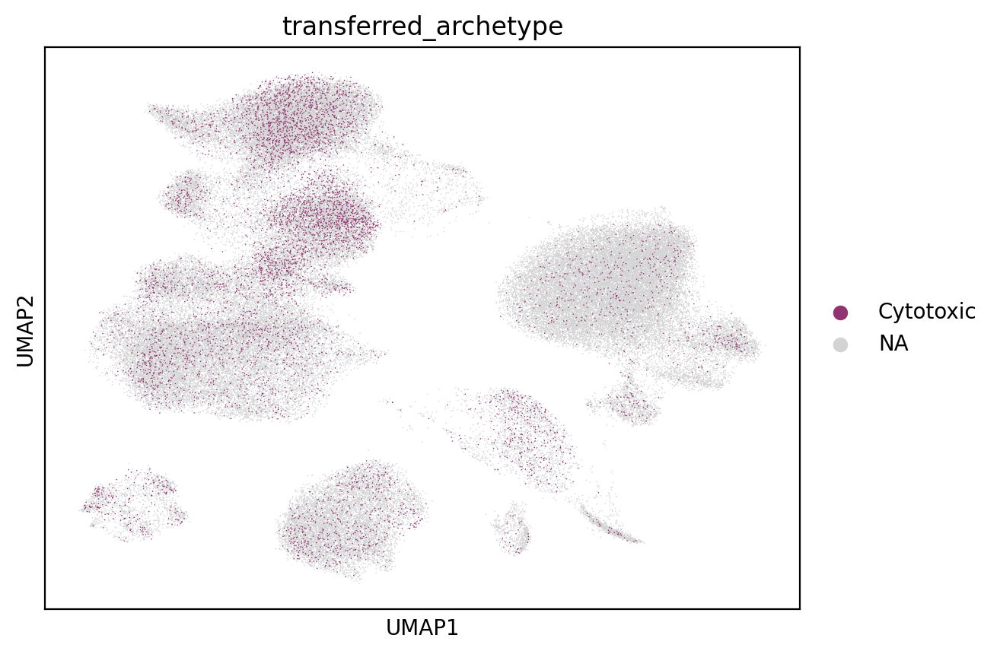

In [128]:
# Plot only a selected archetype
sc.pl.umap(
    adata_subsample,
    color="transferred_archetype",
    groups=["Cytotoxic"],
    na_color="lightgrey",
)

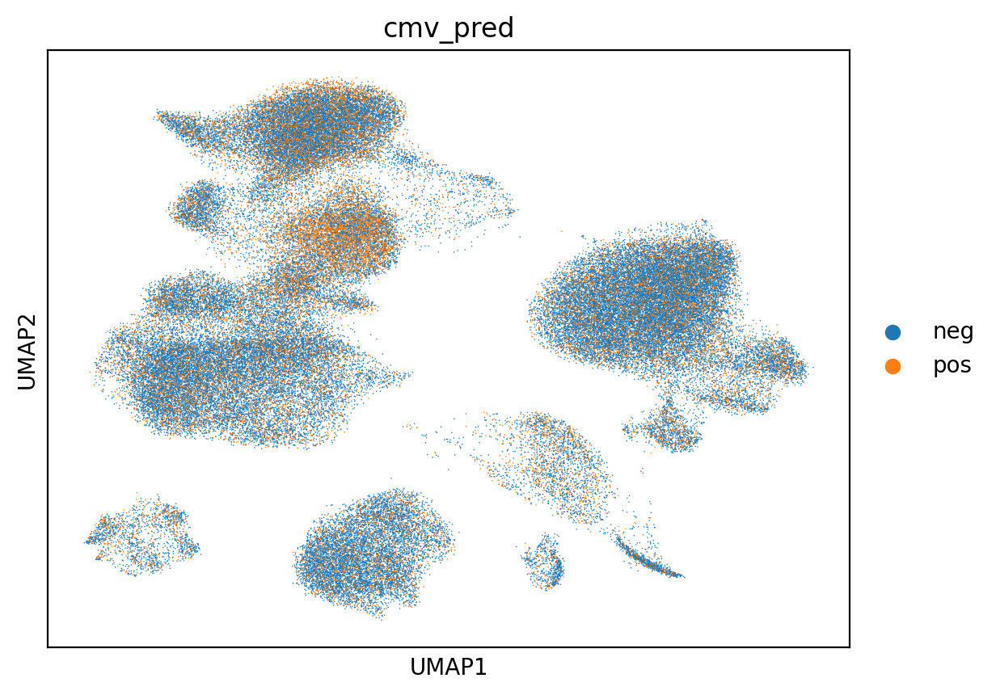

In [118]:
# Predicted CMV status
sc.pl.umap(adata_subsample, color="cmv_pred")

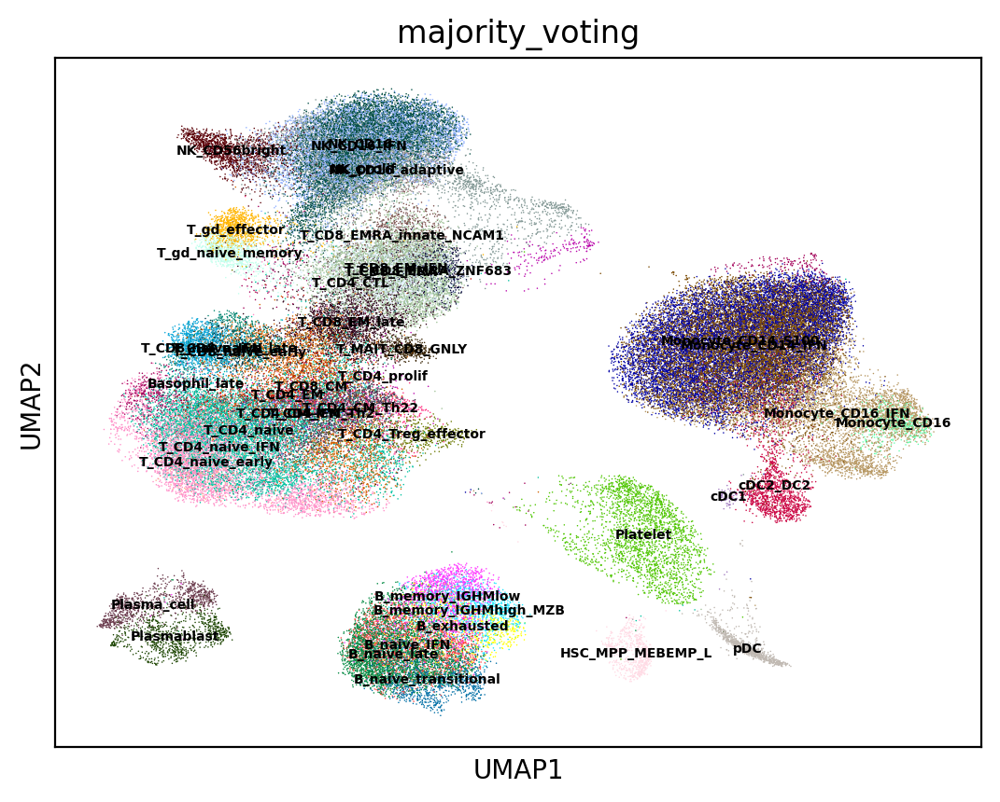

In [124]:
# Cell type labels
sc.pl.umap(adata_subsample, color="majority_voting", legend_loc="on data", legend_fontsize=5)

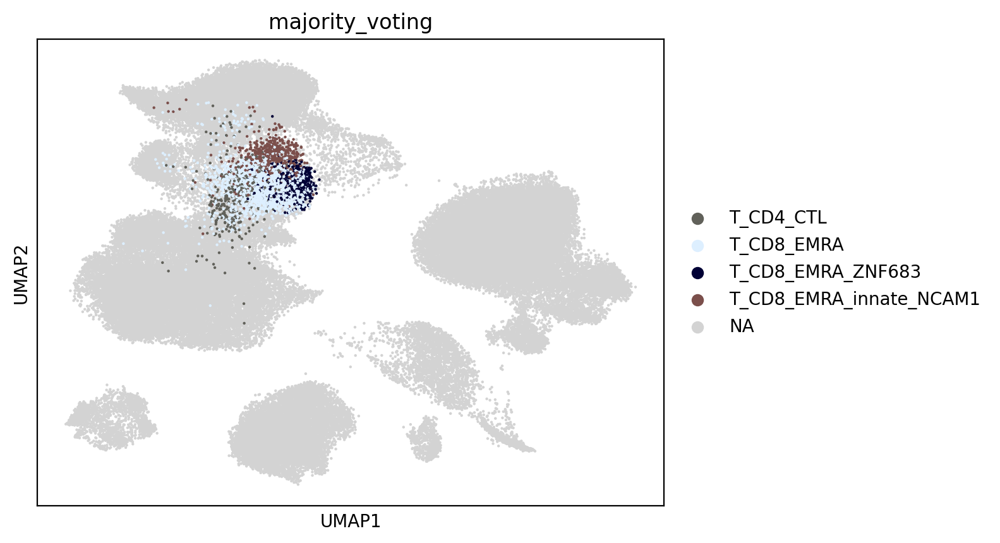

In [136]:
# Plot T cell states associated with the cytotoxic archetype and CMV positivity
sc.pl.umap(adata_subsample,
           color="majority_voting",
           groups=["T_CD8_EMRA_innate_NCAM1", "T_CD8_EMRA_innate_EOMES", "T_CD8_EMRA_ZNF683", "T_CD8_EMRA", "T_CD4_CTL"],
           na_color="lightgrey",
           size=10)

From the plots we can visually see how the cytotoxic archetype and CMV positivity are found in the same regions of the cell embedding as the T cell states associated with these phenotypes. 

In [92]:
# Save sample-level AnnData with archetype and CMV annotations and reference embedding
adata_frac_mapped.write_h5ad("haniffa21_frac_mapped.h5ad")

In [4]:
session_info.show()